# Mean density plot as a function of radius and phase diagram

In [1]:
import yt
yt.set_log_level(50)
import unyt
from astropy.table import Table
import helper_functions as hf
import numpy as np
import matplotlib.pyplot as plt

# Load the simulation data

In [2]:
df='/lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine'

target_sink=5

In [10]:
# Snapshot number
output=107

In [11]:
ds=yt.load(hf.info_file(output,df))

ad=ds.all_data(); # Load a data object that contains all data

Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00107/info_00107.txt


In [12]:
# Load position from file at this output
filename=f'{df}/output_{str(output).zfill(5)}/sink_{str(output).zfill(5)}.csv'
t = Table.read(filename,format='ascii',names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])
print("This output contains",len(t),"black holes")

This output contains 671 black holes


In [13]:
# Find position of target BH
sink_pos=t[t['sink_id']==target_sink]['x','y','z'] # Position on 6th sink
sink_pos_ds=ds.arr(sink_pos[0].as_void().tolist(),'code_length') #Position converted to something the dataset understands by adding units and stripping formatting
print(sink_pos_ds)

[0.50408424 0.50046263 0.50457984] code_length


In [14]:
sp = ds.sphere(sink_pos_ds, ds.quan(5, 'kpc'))

cr = ds.cut_region(sp, ["obj['gas', 'temperature'] < 10 ** 4.5"])

# Load time series of the target black hole

In [8]:
# Load timeseries for most massive black hole
ts=hf.SinkDataLoader(df,sinkid=target_sink)

index = np.argmin(np.abs(ts.data["z"] - ds.current_redshift))

In [9]:
bondi = ts.data["Rb"][index]
bhl = ts.data["Rbhl"][index]

print(bondi)
print(bhl)

8.84373529375691
3.6190771314289


# Phase Diagram


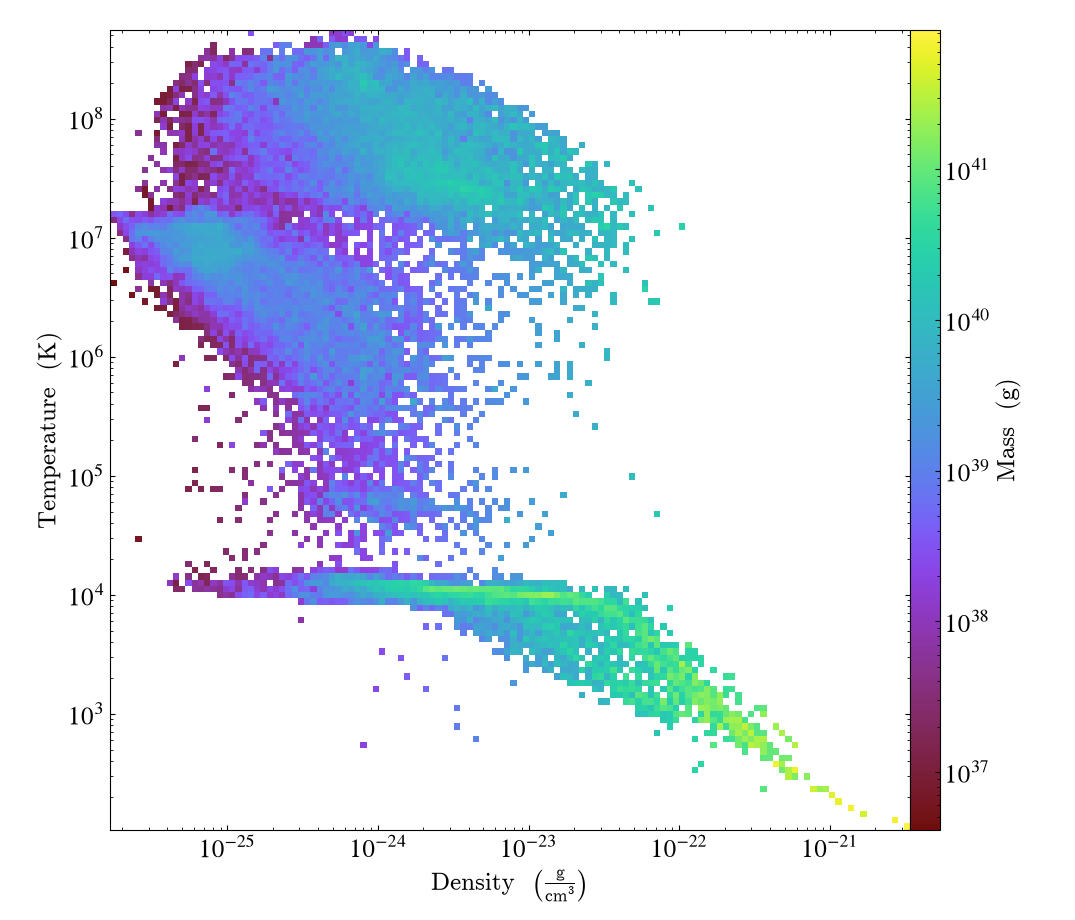

In [15]:
plot = yt.PhasePlot(
    sp, ("gas", "density"), ("gas", "temperature"), [("gas", "mass")], weight_field=None
)

# plot.save("fig/phase_1_1.png")
plot.show()

# Volume Weighted radial density profile

Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00105/info_00105.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00106/info_00106.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00107/info_00107.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00108/info_00108.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00109/info_00109.txt



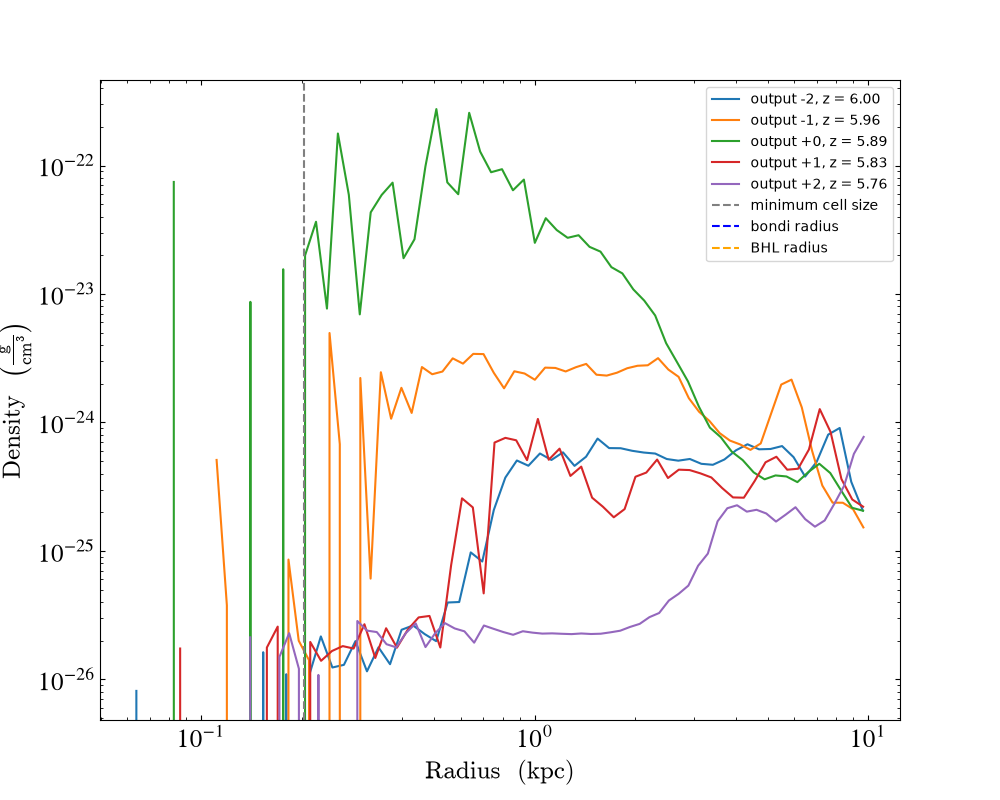

In [ ]:
outputs = range(output - 2, output + 3)

profiles, labels = [], []
bondi_radii, bhl_radii, redshifts = [], [], []

ts=hf.SinkDataLoader(df,sinkid=target_sink)

for out in outputs:
    ds = yt.load(hf.info_file(out, df))

    index = np.argmin(np.abs(ts.data["z"] - ds.current_redshift))

    bondi = ts.data["Rb"][index]
    bhl = ts.data["Rbhl"][index]
    redshift = ts.data["z"][index]

    bondi_radii.append(bondi)
    bhl_radii.append(bhl)
    redshifts.append(redshift)

    filename=f'{df}/output_{str(out).zfill(5)}/sink_{str(out).zfill(5)}.csv'
    t = Table.read(filename,format='ascii',names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])

    sink_pos=t[t['sink_id']==target_sink]['x','y','z']
    sink_pos_ds=ds.arr(sink_pos[0].as_void().tolist(),'code_length')

    sp = ds.sphere(sink_pos_ds, ds.quan(10, 'kpc'))

    cr = ds.cut_region(sp, ["obj['gas', 'temperature'] < 10 ** 4.5"])

    profiles.append(
        yt.create_profile(
            cr,
            [("index", "radius")],
            [("gas", "density")],
            weight_field= ("gas", "cell_volume"),
            units={("index", "radius"): "kpc"},
            n_bins=64
        )
    )

    labels.append(f'output {out - output:+d}, z = {ds.current_redshift:.2f}')

    if out == output:
        dx = ds.index.get_smallest_dx().to("kpc")

plot = yt.ProfilePlot.from_profiles(profiles, labels=labels)
plot.set_unit(('index', 'radius'), 'kpc')
plot.render()

target_z = redshifts[2]
R_bondi = np.mean(bondi_radii)
R_bhl = np.mean(bhl_radii)

ax = plot.plots[('gas', 'density')].axes
ax.axvline(dx, ls='--', c='grey', label='minimum cell size')
ax.axvline(R_bondi * 1e-3, ls='--', c='blue', label='bondi radius')
ax.axvline(R_bhl * 1e-3, ls='--', c='orange', label='BHL radius')
ax.legend()
plot.show()
# plot.save("fig/radial_profile/most_massive_volume_2.png")

In [32]:
print(dx)

print(cr.index.get_smallest_dx().to("kpc").min())

0.20338226443973076 kpc
0.20728637521426457 kpc


# Mass weighted radial density profile

Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00098/info_00098.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00099/info_00099.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00100/info_00100.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00101/info_00101.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00102/info_00102.txt



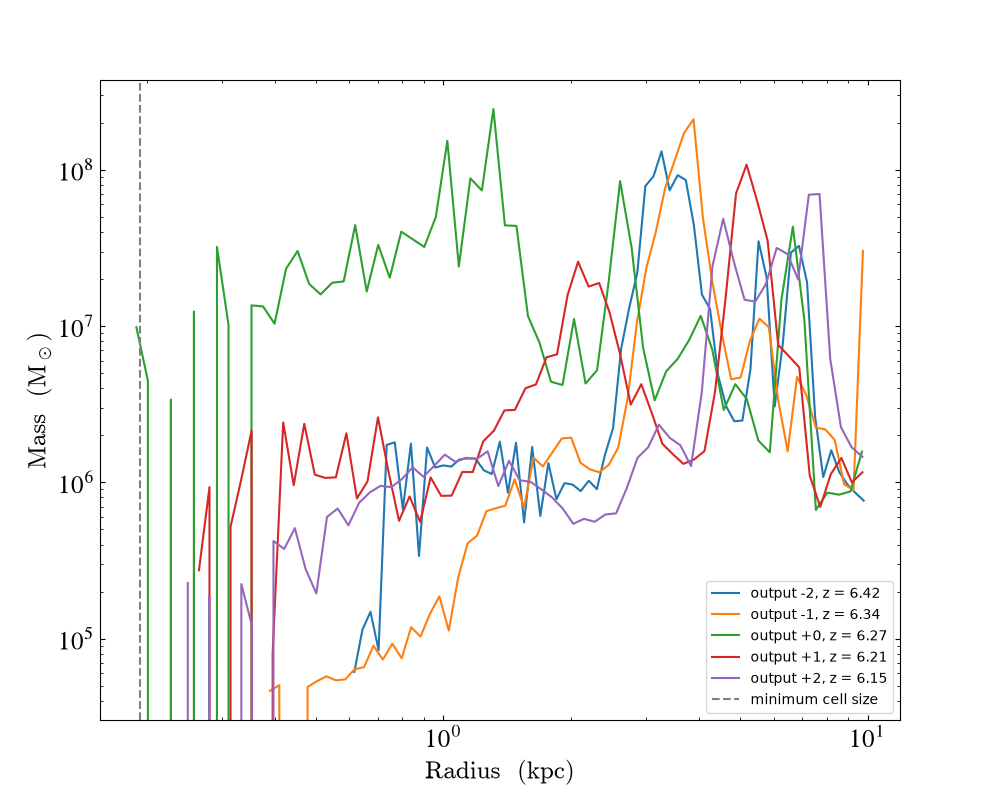

In [ ]:
outputs = range(output - 2, output + 3)

profiles, labels = [], []
for out in outputs:
    ds = yt.load(hf.info_file(out, df))

    filename=f'{df}/output_{str(out).zfill(5)}/sink_{str(out).zfill(5)}.csv'
    t = Table.read(filename,format='ascii',names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])

    sink_pos=t[t['sink_id']==target_sink]['x','y','z']
    sink_pos_ds=ds.arr(sink_pos[0].as_void().tolist(),'code_length')

    sp = ds.sphere(sink_pos_ds, ds.quan(10, 'kpc'))
    cr = ds.cut_region(sp, ["obj['gas', 'temperature'] < 10 ** 4.5"])

    profiles.append(
        yt.create_profile(
            cr,
            [("index", "radius")],
            [("gas", "mass")],
            weight_field= ("gas", "mass"),
            units={("index", "radius"): "kpc"}
        )
    )

    labels.append(f'output {out - output:+d}, z = {ds.current_redshift:.2f}')
plot = yt.ProfilePlot.from_profiles(profiles, labels=labels)
plot.set_unit(('index', 'radius'), 'kpc')
plot.set_unit(('gas', 'mass'), 'Msun')
plot.render()

ax = plot.plots[('gas', 'mass')].axes
ax.axvline(0.193, ls='--', c='grey', label='minimum cell size')
ax.legend()

plot.show()
# plot.save("fig/radial_profile/most_massive_mass_2.png")

# Accumulated Mass

Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00098/info_00098.txt


Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00099/info_00099.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00100/info_00100.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00101/info_00101.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00102/info_00102.txt



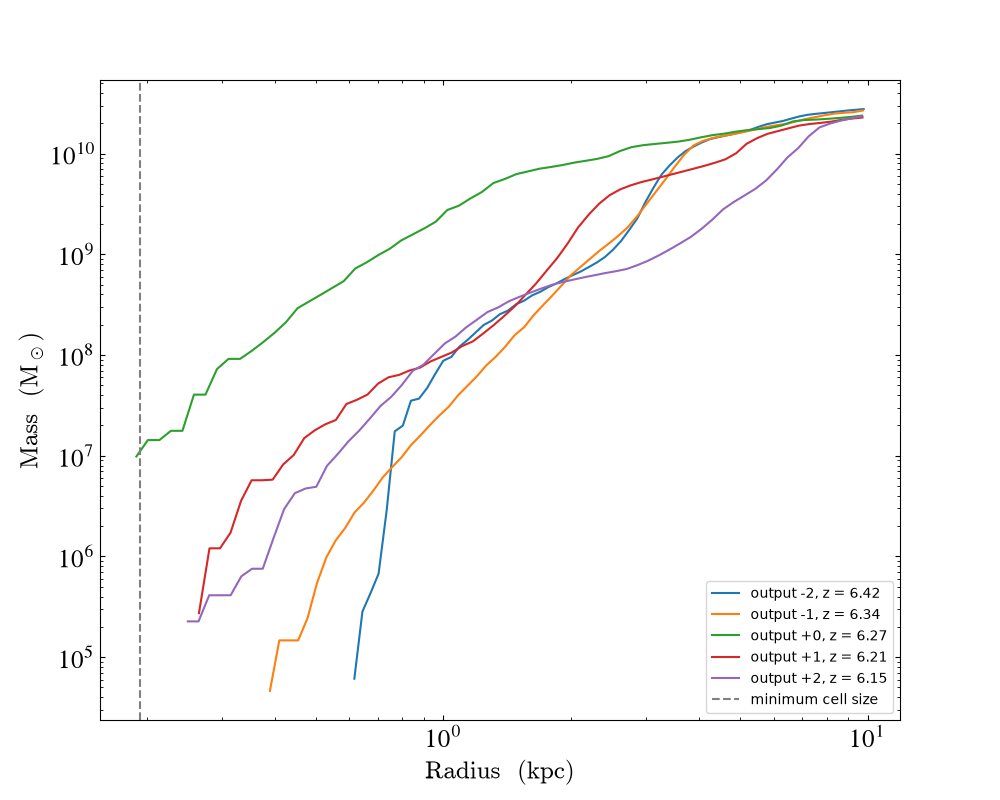

In [4]:
outputs = range(output - 2, output + 3)

profiles, profiles_all, labels = [], [], []
for out in outputs:
    ds = yt.load(hf.info_file(out, df))

    filename=f'{df}/output_{str(out).zfill(5)}/sink_{str(out).zfill(5)}.csv'
    t = Table.read(filename,format='ascii',names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])

    sink_pos=t[t['sink_id']==target_sink]['x','y','z']
    sink_pos_ds=ds.arr(sink_pos[0].as_void().tolist(),'code_length')

    sp = ds.sphere(sink_pos_ds, ds.quan(10, 'kpc'))

    cr = ds.cut_region(sp, ["obj['gas', 'temperature'] < 10 ** 4.5"])

    profiles.append(
        yt.create_profile(
            cr,
            [("index", "radius")],
            [("gas", "mass")],
            weight_field= None,
            units={("index", "radius"): "kpc"},
            accumulation=True
        )
    )

    labels.append(f'output {out - output:+d}, z = {ds.current_redshift:.2f}')
    
plot = yt.ProfilePlot.from_profiles(profiles, labels=labels)
plot.set_unit(('index', 'radius'), 'kpc')
plot.set_unit(('gas', 'mass'), 'Msun')
plot.render()

ax = plot.plots[('gas', 'mass')].axes
ax.axvline(0.193, ls='--', c='grey', label='minimum cell size')

ax.legend()

plot.show()
# plot.save('fig/radial_profile/most_massive_accumlation_2.png')

In [ ]:
outputs = range(output - 2, output + 3)
kw = dict(weight_field=None,
          units={("index","radius"): "kpc"},
          accumulation=True,
          extrema={("index","radius"): ((0.2,'kpc'), (10,'kpc'))},
          n_bins=128, logs={("index","radius"): True})

r_bins = None

r_list, Mcold_list, Mall_list, labels = [], [], [], []
for out in outputs:
    ds = yt.load(hf.info_file(out, df))
    filename = f'{df}/output_{str(out).zfill(5)}/sink_{str(out).zfill(5)}.csv'
    t = Table.read(filename, format='ascii', names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])
    c = ds.arr(t[t['sink_id']==target_sink]['x','y','z'][0].as_void().tolist(), 'code_length')

    sp = ds.sphere(c, (10, 'kpc'))
    cr = sp.cut_region(["obj['gas','temperature'] < 10**4.5"])

    if r_bins is None:
        p_all  = yt.create_profile(sp, [("index","radius")], [("gas","mass")], **kw)
        r_bins = p_all.x_bins
    else:
        p_all  = yt.create_profile(sp, [("index","radius")], [("gas","mass")], override_bins={("index", "radius"): r_bins}, **kw)
    
    p_cold = yt.create_profile(cr, [("index","radius")], [("gas","mass")], override_bins={("index", "radius"): r_bins}, **kw)

    r_list.append(p_all.x.to('kpc').value)
    Mcold_list.append(p_cold[("gas","mass")].to('Msun').value)
    Mall_list.append(p_all[("gas","mass")].to('Msun').value)
    labels.append(f'output {out - output:+d}, z = {ds.current_redshift:.2f}')

    if out == output:
        dx = cr.index.get_smallest_dx().to("kpc").min()
        print(dx)

Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00098/info_00098.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00099/info_00099.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00100/info_00100.txt
0.1928059360594453 kpc
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00101/info_00101.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00102/info_00102.txt


In [7]:
print(np.shape(r_list))
print(np.shape(Mcold_list))
print(r_bins)
print(r_bins.shape)

(5, 128)
(5, 128)
[ 0.2         0.2062069   0.21260643  0.21920457  0.22600748  0.23302151
  0.24025322  0.24770936  0.2553969   0.26332302  0.27149512  0.27992084
  0.28860805  0.29756486  0.30679964  0.31632101  0.32613788  0.33625941
  0.34669506  0.35745457  0.368548    0.37998571  0.39177838  0.40393703
  0.41647302  0.42939806  0.44272422  0.45646395  0.47063008  0.48523586
  0.50029492  0.51582133  0.53182959  0.54833466  0.56535196  0.58289738
  0.60098732  0.61963867  0.63886885  0.65869584  0.67913814  0.70021486
  0.72194569  0.74435092  0.76745149  0.79126898  0.81582562  0.84114437
  0.86724888  0.89416353  0.92191346  0.95052459  0.98002366  1.01043822
  1.04179667  1.07412833  1.10746338  1.14183296  1.17726919  1.21380517
  1.25147502  1.29031394  1.3303582   1.37164522  1.41421356  1.45810299
  1.50335451  1.55001038  1.5981142   1.6477109   1.6988468   1.75156968
  1.8059288   1.86197492  1.9197604   1.97933923  2.04076706  2.10410127
  2.16940103  2.23672733  2.30614

/tmp/ipykernel_718432/1627737524.py:8: RuntimeWarning: invalid value encountered in divide
  ax[1].semilogx(r, np.where(Ma > 0, Mc / Ma, np.nan), '-', c=col)


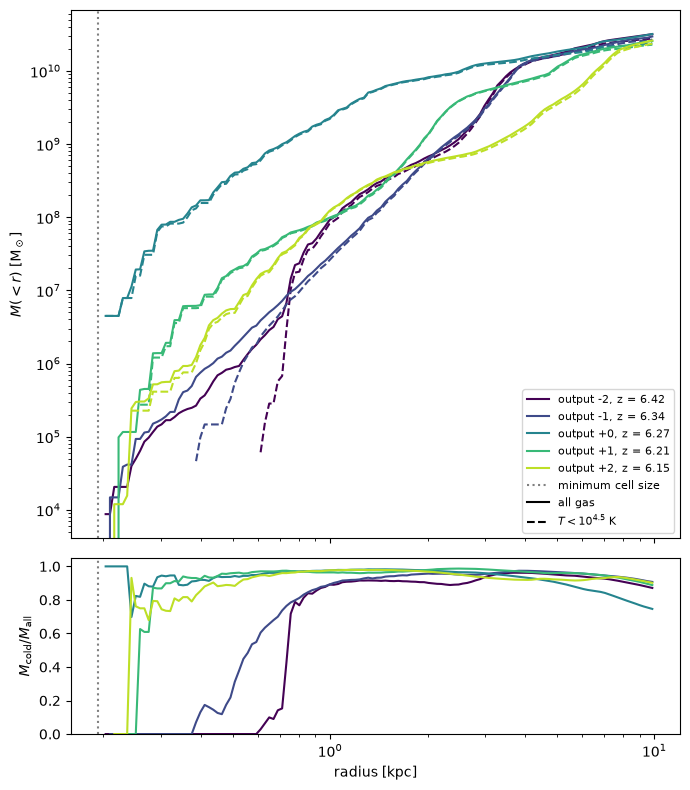

In [11]:
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(7, 8), height_ratios= [3, 1])
cmap = plt.colormaps['viridis']
colors = cmap(np.linspace(0, 0.9, len(labels)))

for r, Mc, Ma, lab, col in zip(r_list, Mcold_list, Mall_list, labels, colors):
    ax[0].loglog(r, Ma, '-',  c=col, label=lab)
    ax[0].loglog(r, np.where(Mc > 0, Mc, np.nan), '--', c=col)
    ax[1].semilogx(r, np.where(Ma > 0, Mc / Ma, np.nan), '-', c=col)

for a in ax:
    a.axvline(dx, ls=':', c='grey', label='minimum cell size')
ax[0].set_ylabel(r'$M(<r)$ [M$_\odot$]')
ax[0].plot([], [], 'k-',  label='all gas')
ax[0].plot([], [], 'k--', label=r'$T < 10^{4.5}$ K')
ax[0].legend(fontsize=8)
ax[1].set_ylabel(r'$M_{\rm cold}/M_{\rm all}$')
ax[1].set_ylim(0, 1.05)
ax[1].set_xlabel('radius [kpc]')
plt.tight_layout();
# plt.savefig("fig/density_plot/ratio_cold_all_1_2");

# Density vs time at a fixed radius

In [9]:
output = 100
target_sink=5

In [11]:
ts   = hf.SinkDataLoader(df, sinkid=target_sink)
time = Table.read(df+'/ADAPTAclump_maps/output_step_redshift.txt', format='ascii')
snap_t   = np.array([float(t) for t in time['time']])
snap_out = np.array([int(o) for o in time['output']])

mask = (snap_out >= output - 10) & (snap_out <= output + 10)

In [12]:
t_gyr  = np.asarray(ts.data["time"])
dt_myr = np.diff(t_gyr) * 1e3

print(np.percentile(dt_myr, [1, 25, 50, 75, 99]))

[0.00331445 0.00427141 0.00591099 0.00716291 0.02213164]


In [8]:
r0  = 1.0
dr  = 0.5

ds  = yt.load(hf.info_file(output, df))
filename = f'{df}/output_{str(output).zfill(5)}/sink_{str(output).zfill(5)}.csv'
t   = Table.read(filename, format='ascii', names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])
sel = t[t['sink_id'] == target_sink]

c    = ds.arr(sel['x','y','z'][0].as_void().tolist(),    'code_length')
v_bh = ds.arr(sel['vx','vy','vz'][0].as_void().tolist(), 'code_velocity')

t_snap = snap_t[snap_out == output][0]
i = np.argmin(np.abs(ts.data['time'].to('Gyr').value - t_snap))

sp = ds.sphere(c, (10, 'kpc'))
sp.set_field_parameter('bulk_velocity', v_bh)

r  = sp['index','radius'].to('kpc').value
m  = sp['gas','mass'].to('Msun').value
vr = sp['gas','radial_velocity'].to('kpc/yr').value
s  = np.abs(r - r0) < dr/2

Min  = (m[s & (vr < 0)] * vr[s & (vr < 0)]).sum() / dr
Mout = (m[s & (vr > 0)] * vr[s & (vr > 0)]).sum() / dr
dx = sp['index', 'dx'].to('pc')

print('v_bh csv  :', v_bh.to('km/s'))
print('v_bh log  :', ts.data['vsink'][i])
print('pos  csv  :', c.to('pc'))
print('pos  log  :', ts.data['position'][i])
print('dx', dx.min())

Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00059/info_00059.txt
v_bh csv  : [-23.60200529 267.08816901  37.39063474] km/s
v_bh log  : [-23.52518418 267.01784173  37.27965804]
pos  csv  : [37055900.29854417 36747546.99220443 37037191.78661369] pc
pos  log  : [37055900.2971975 36747546.9935555 37037191.7889304]
dx 140.198858677261 pc


In [41]:
dx_min = dx.min()
target_scale_factor = 1 / (1 + ds.current_redshift)

print(target_scale_factor)
print(ds.current_redshift)

0.100003223852494
8.999677625143491


In [7]:
rho_rt, t_list = [], []
radii = [1.0, 2.0, 4.0, 8.0]
Min_list = {r0: [] for r0 in radii}
Mout_list = {r0: [] for r0 in radii}

for out, t_out in zip(snap_out[mask], snap_t[mask]):
    ds  = yt.load(hf.info_file(out, df))
    filename=f'{df}/output_{str(out).zfill(5)}/sink_{str(out).zfill(5)}.csv'
    t = Table.read(filename,format='ascii',names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])
    sel = t[t['sink_id'] == target_sink]
    c  = ds.arr(sel['x','y','z'][0].as_void().tolist(), 'code_length')
    v_bh = ds.arr(sel['vx','vy','vz'][0].as_void().tolist(), 'code_velocity')
    sp = ds.sphere(c, (10, 'kpc'))
    sp.set_field_parameter('bulk_velocity', v_bh)
    prof = yt.create_profile(sp, [("index","radius")], [("gas","density")],
                             weight_field=("gas","cell_volume"),
                             units={("index","radius"):"kpc"},
                             extrema={("index","radius"):(0.5, 10)})
    rho = prof[("gas","density")].to('g/cm**3').v
    rho[~prof.used] = np.nan
    rho_rt.append(rho)
    t_list.append(t_out)

    r  = sp['index','radius'].to('kpc').value
    m  = sp['gas','mass'].to('Msun').value
    vr = sp['gas','radial_velocity'].to('kpc/yr').value

    for r0 in radii:
        dr = 0.5
        s = np.abs(r - r0) < dr/2
        Min_list[r0].append((m[s & (vr < 0)] * vr[s & (vr < 0)]).sum() / dr)
        Mout_list[r0].append((m[s & (vr > 0)] * vr[s & (vr > 0)]).sum() / dr)

r_bins = prof.x.to('kpc').value
rho_rt = np.array(rho_rt)
t_list = np.array(t_list)
Min_list  = {k: np.array(v) for k, v in Min_list.items()}
Mout_list = {k: np.array(v) for k, v in Mout_list.items()};


Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00090/info_00090.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00091/info_00091.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00092/info_00092.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00093/info_00093.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00094/info_00094.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00095/info_00095.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00096/info_00096.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00097/info_00097.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00098/info_00098.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00099/info_00099.txt
Opening /l

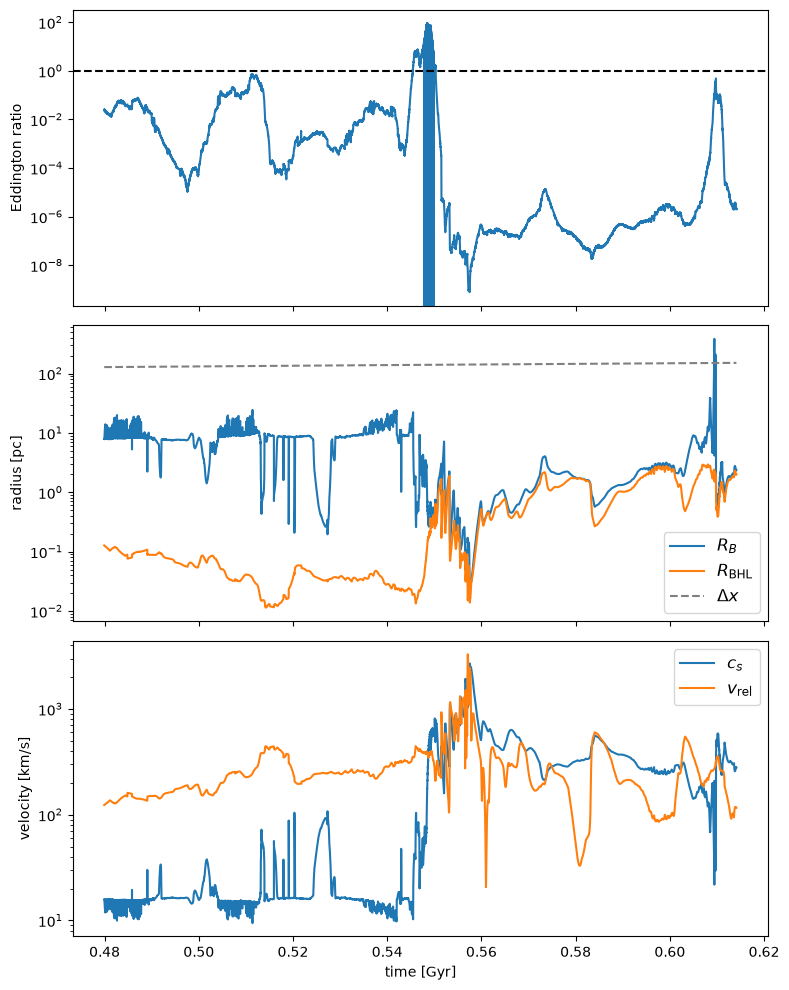

In [39]:
d = ts.data
times = d['time'].to('Gyr').value
aexp = d['aexp'].value
M = d['BHmass'].value

m = (times > snap_t[mask][0]) & (times < snap_t[mask][-1])

comoving = dx_min / target_scale_factor

Rb   = np.asarray(d['Rb'])
Rbhl = np.asarray(d['Rbhl'])
fedd = np.asarray((d['dotMaccr'] / d['dotMedd']).value)

G = 4.30e-3
cs2   = 2 * G * M / Rb
v2    = 2 * G * M / Rbhl - cs2
veff2 = cs2 + v2

fig, ax = plt.subplots(3, 1, sharex=True, figsize=(8, 10))
ax[0].semilogy(times[m], fedd[m])
ax[0].axhline(1, ls='--', c='k'); ax[0].set_ylabel('Eddington ratio')
ax[1].semilogy(times[m], Rb[m],   label=r'$R_B$')
ax[1].semilogy(times[m], Rbhl[m], label=r'$R_{\rm BHL}$')
ax[1].plot(times[m], comoving * aexp[m], ls='--', c='grey', label=r'$\Delta x$')
ax[1].set_ylabel('radius [pc]')
ax[1].legend(fontsize=12)
# ax[2].plot(times[m], np.sqrt(veff2[m]))
ax[2].plot(times[m], np.sqrt(cs2[m]), label=r'$c_s$')
ax[2].plot(times[m], np.sqrt(v2[m]), label=r'$v_\mathrm{rel}$')
ax[2].set_ylabel('velocity [km/s]')
ax[2].legend(fontsize=12)
ax[2].set_xlabel('time [Gyr]')
ax[2].set_yscale('log')
plt.tight_layout()
plt.savefig(f'fig/bondi/bondi_2_{output}')

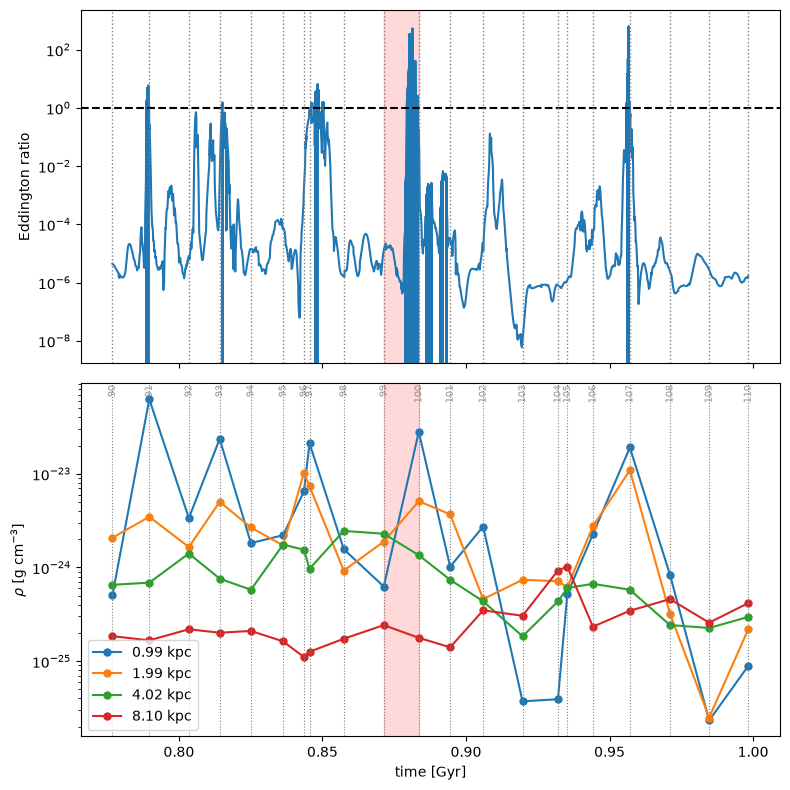

In [ ]:
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(8, 8))
times = ts.data['time'].to('Gyr').value
m = (times > t_list[0]) & (times < t_list[-1])
axes[0].semilogy(times[m], (ts.data['dotMaccr']/ts.data['dotMedd'])[m])
axes[0].axhline(1, ls='--', c='k')
axes[0].set_ylabel('Eddington ratio')

output_labels = [str(o) for o in snap_out[mask]]

for r0 in [1.0, 2.0, 4.0, 8.0]:
    j = np.argmin(np.abs(r_bins - r0))
    axes[1].semilogy(t_list, rho_rt[:, j], 'o-', ms=5, label=f'{r_bins[j]:.2f} kpc')

t_before, t_target = snap_t[snap_out == output - 1][0], snap_t[snap_out == output][0]

axes[0].axvspan(t_before, t_target, color='r', alpha=0.15)
axes[1].axvspan(t_before, t_target, color='r', alpha=0.15)

ymin1, ymax1 = axes[1].get_ylim()
label_y = ymax1 * 0.95

for tt, label in zip(t_list, output_labels): 
    axes[0].axvline(tt, color='grey', ls=':', lw=1)
    axes[1].axvline(tt, color='grey', ls=':', lw=0.8)
    axes[1].text(tt, label_y, label, color='grey', fontsize=7, rotation=90, va='top', ha='center', alpha=0.8)

axes[-1].set_ylabel(r'$\rho$ [g cm$^{-3}$]') 
axes[-1].set_xlabel('time [Gyr]')
axes[-1].legend()
plt.tight_layout()
# plt.savefig("fig/density_time_1");

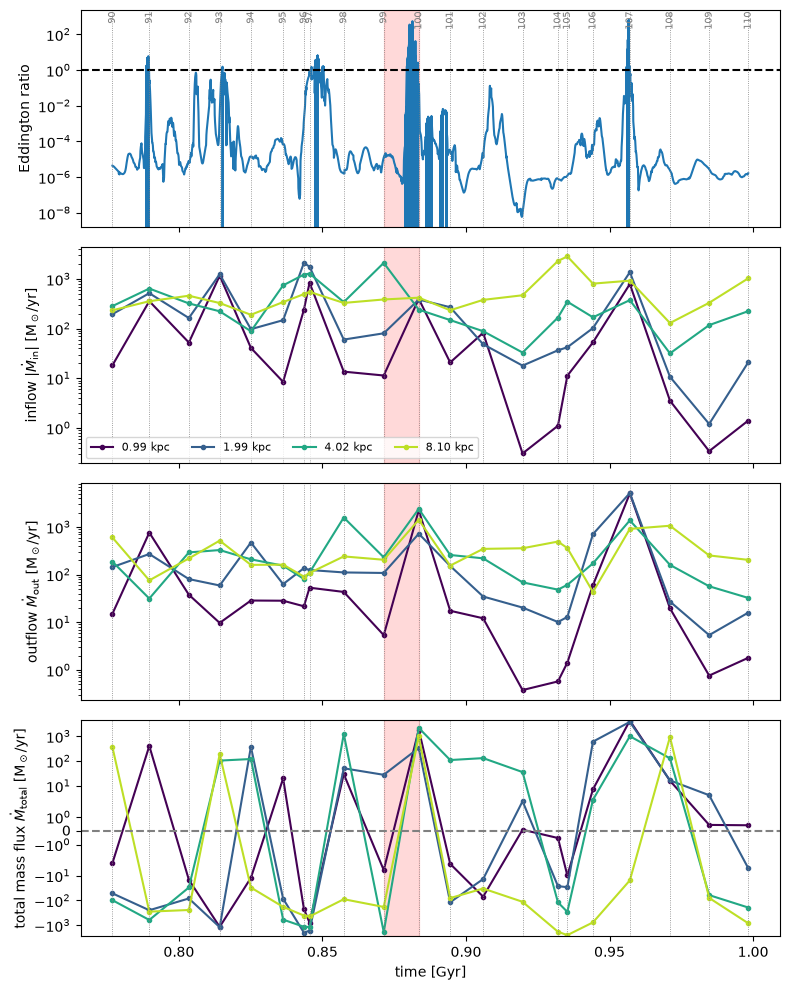

In [ ]:
radii  = [1.0, 2.0, 4.0, 8.0]
cmap = plt.colormaps['viridis']
colors = cmap(np.linspace(0, 0.9, len(radii)))

fig, axes = plt.subplots(4, 1, sharex=True, figsize=(8, 10))
times = ts.data['time'].to('Gyr').value
m = (times > t_list[0]) & (times < t_list[-1])
axes[0].semilogy(times[m], (ts.data['dotMaccr']/ts.data['dotMedd'])[m])
axes[0].axhline(1, ls='--', c='k')
axes[0].set_ylabel('Eddington ratio')

for r0, col in zip(radii, colors):
    j = np.argmin(np.abs(r_bins - r0))
    axes[1].semilogy(t_list, -Min_list[r0], 'o-', c=col, ms=3, label=f'{r_bins[j]:.2f} kpc')
    axes[2].semilogy(t_list,  Mout_list[r0], 'o-', c=col, ms=3)
    axes[3].plot(t_list, Min_list[r0] + Mout_list[r0], 'o-', c=col, ms=3)
axes[1].set_ylabel(r'inflow $|\dot M_{\rm in}|$ [M$_\odot$/yr]')
axes[2].set_ylabel(r'outflow $\dot M_{\rm out}$ [M$_\odot$/yr]')
axes[3].set_ylabel(r'total mass flux $\dot M_{\rm total}$ [M$_\odot$/yr]')
axes[1].legend(fontsize=8, loc='lower left', ncol=4)

axes[3].axhline(0, c='grey', ls='--')
axes[3].set_yscale('symlog')

t_before = snap_t[snap_out == output - 1][0]
t_target = snap_t[snap_out == output][0]
for ax in axes:
    ax.axvspan(t_before, t_target, color='r', alpha=0.15)
    for tt in t_list:
        ax.axvline(tt, color='grey', ls=':', lw=0.6)

ymax = axes[0].get_ylim()[1]
for tt, out in zip(t_list, snap_out[mask]):
    axes[0].text(tt, ymax*0.8, str(out), color='grey', fontsize=7, rotation=90, va='top', ha='center')

axes[-1].set_xlabel('time [Gyr]')
plt.tight_layout()
# plt.savefig("fig/mass_flux_1")

# Filtering only cool gas from phase diagram

In [ ]:
t_list = []
rho_cold = []

kr = dict(weight_field=None, units={("index", "radius"): "kpc"},
          extrema={("index", "radius"): (0.5, 10)}, n_bins=20)
r_bins = None

for out, t_out in zip(snap_out[mask], snap_t[mask]):
    ds  = yt.load(hf.info_file(out, df))
    filename=f'{df}/output_{str(out).zfill(5)}/sink_{str(out).zfill(5)}.csv'
    t = Table.read(filename,format='ascii',names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])
    sel = t[t['sink_id'] == target_sink]
    c  = ds.arr(sel['x','y','z'][0].as_void().tolist(), 'code_length')
    v_bh = ds.arr(sel['vx','vy','vz'][0].as_void().tolist(), 'code_velocity')
    sp = ds.sphere(c, (10, 'kpc'))
    cr = sp.cut_region(["obj['gas', 'temperature'] < 10**4.5"])
    if r_bins is None:
        Mc_profile = yt.create_profile(cr, [("index", "radius")], [("gas", "mass")], **kr)
        Mc = Mc_profile[("gas", "mass")]
        r_bins = Mc_profile.x_bins.to("kpc").v
    else:
        Mc = yt.create_profile(cr, [("index", "radius")], [("gas", "mass")], **kr, override_bins={("index", "radius"): r_bins})[("gas", "mass")]
    V = yt.create_profile(sp, [("index", "radius")], [("gas", "cell_volume")], **kr, override_bins={("index", "radius"): r_bins})[("gas", "cell_volume")]
    rho_c = (Mc/V).to("g/cm**3").v
    rho_c[rho_c==0] = np.nan
    rho_cold.append(rho_c)
    t_list.append(t_out)

Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00090/info_00090.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00091/info_00091.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00092/info_00092.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00093/info_00093.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00094/info_00094.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00095/info_00095.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00096/info_00096.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00097/info_00097.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00098/info_00098.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00099/info_00099.txt
Opening /l

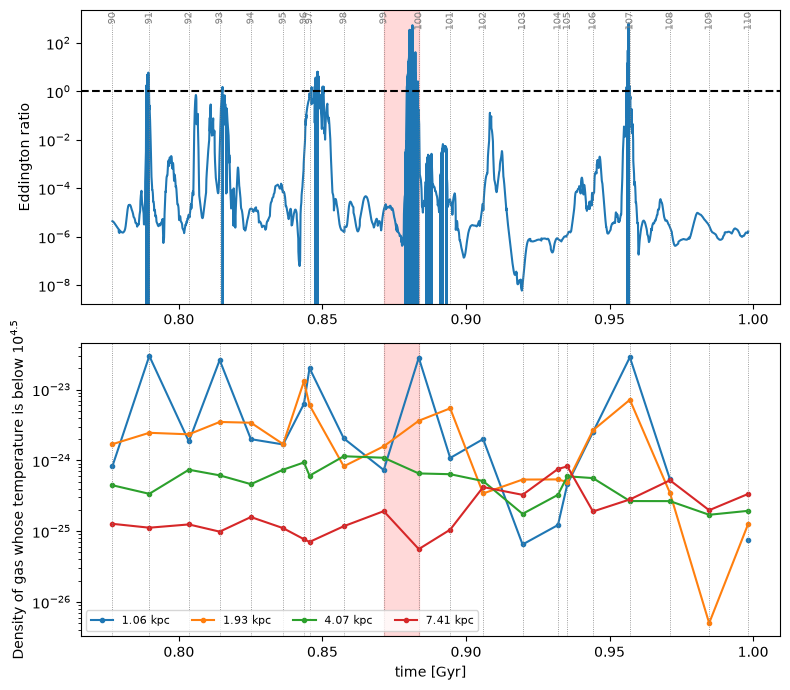

In [15]:
radii = [1.0, 2.0, 4.0, 8.0]
cmap = plt.colormaps["viridis"]
colors = cmap(np.linspace(0, 0.9, len(radii)))

fig, axes = plt.subplots(2, 1, figsize=(8, 7))
times = ts.data['time'].to('Gyr').value
m = (times > t_list[0]) & (times < t_list[-1])
axes[0].semilogy(times[m], (ts.data['dotMaccr']/ts.data['dotMedd'])[m])
axes[0].axhline(1, ls='--', c='k')
axes[0].set_ylabel('Eddington ratio')

rho_cold = np.array(rho_cold)

for col, radius in zip(colors, radii):
    j = np.argmin(np.abs(r_bins - radius))
    axes[1].semilogy(t_list, rho_cold[:, j], 'o-', ms=3, label=f'{r_bins[j]:.2f} kpc')

axes[1].set_ylabel(r'Density of gas whose temperature is below $10^{4.5}$')
axes[-1].set_xlabel('time (Gyr)')

t_before = snap_t[snap_out == output - 1][0]
t_target = snap_t[snap_out == output][0]
for ax in axes:
    ax.axvspan(t_before, t_target, color='r', alpha=0.15)
    for tt in t_list:
        ax.axvline(tt, color='grey', ls=':', lw=0.6)

ymax = axes[0].get_ylim()[1]
for tt, out in zip(t_list, snap_out[mask]):
    axes[0].text(tt, ymax*0.8, str(out), color='grey', fontsize=7, rotation=90, va='top', ha='center')

axes[-1].set_xlabel('time [Gyr]')
axes[1].legend(fontsize=8, loc='lower left', ncol=4)
plt.tight_layout()
plt.savefig('fig/density_time_1_cold_V_right')

In [ ]:
print(np.shape(r_bins))

(21,)
